# 概要 overview

ハイパーパラメータチューニング後のモデル性能を比較
最終的な予測モデルを決定する。

比較するモデルは下記
 1. 勾配ブースティング決定木（GBDT）
 2. RandomForest
 3. ニューラルネットワーク（NN）

## ライブラリ読み込み

In [1]:
import joblib
from pathlib import Path
import torch
from sklearn.preprocessing import StandardScaler

# 自作関数 "src"参照
from src.Data_load_And_Preprocess import data_load_and_preprocess
from src.utils import Plot_actual_vs_predict,evaluation_model
from src.GBDT_model_train import GBDT_train
from src.RandomForest_model_train import RadomForest_train
from src.NN_model_train import NN_train

RANDOM_STATE=42

## データの読み込み

データの読み込みおよび訓練データ・テストデータの分割

In [2]:
X_train, X_test, Y_train, Y_test = data_load_and_preprocess()

Number of samples: 1030
Number of features: 8


## GBDTモデル作成



モデルを保存しました: ./results/GBDT/GBDT_model.pkl


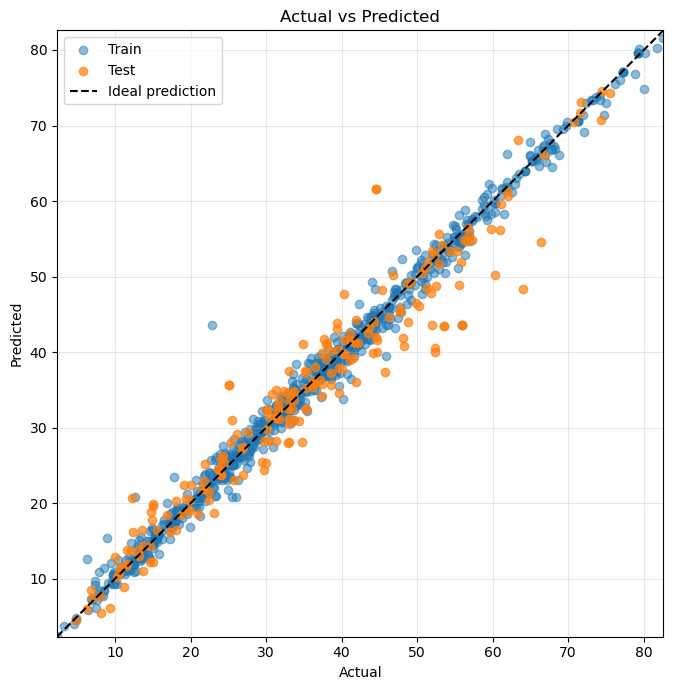

--- 精度評価 ---
RMSE :  train 1.6697   test 4.2087
MAE  :  train 1.0470    test 2.8222
R2   :  train 0.9902     teat 0.9313


In [3]:
params = {
            "objective": "regression",
            'num_class': Y_train.shape[1],
            'metric': 'rmse',
            'boosting_type': 'gbdt',
            'random_state': RANDOM_STATE,
            'verbose': -1,

            "n_estimators": 500,
            
            # チューニング後のパラメータ
            'learning_rate': 0.1,
            'num_leaves': 19,
            'max_depth': 7,
            'min_child_samples': 15,
            'subsample': 0.85,
            'colsample_bytree': 0.71,
            'reg_alpha': 1,
            'reg_lambda': 0.01,
            }


model = GBDT_train(params, X_train, Y_train, X_test, Y_test)


# ==========================================
# 学習済みモデルの保存
# ==========================================
model_save_path = "./results/GBDT/GBDT_model.pkl"

# 保存先ディレクトリを自動作成
Path(model_save_path).parent.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": model,
        "input_dim": X_train.shape[1],
        "output_dim": Y_train.shape[1],
    },
    model_save_path
)

print(f"モデルを保存しました: {model_save_path}")

# ==========================================
# 正解-予測プロット
# ==========================================

# 予測
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

Plot_actual_vs_predict(Y_train,y_train_pred,Y_test,y_test_pred)

# ==========================================
# 精度評価
# ==========================================
evaluation_model(Y_train, y_train_pred, Y_test, y_test_pred)

# Random Forest モデル作成

モデルを保存しました: ./results/RandomForest/RandomForest_model.pkl


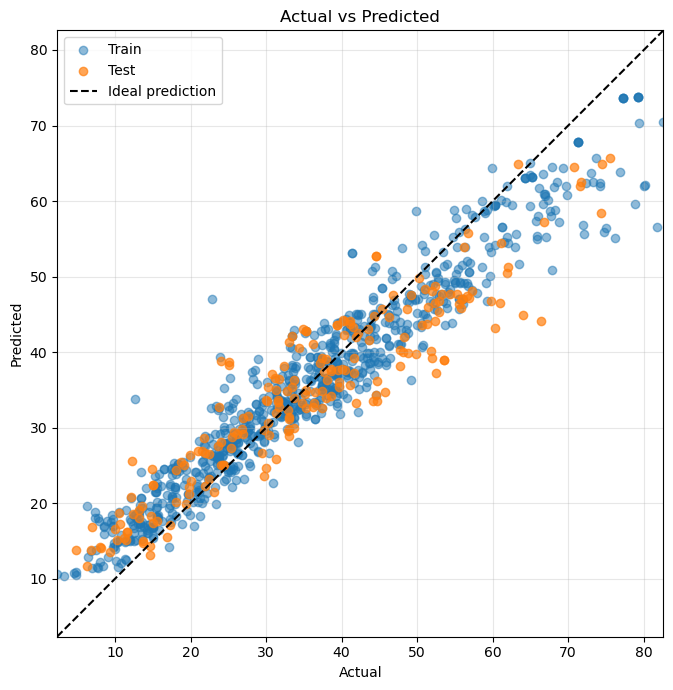

--- 精度評価 ---
RMSE :  train 5.2979   test 6.6947
MAE  :  train 4.0754    test 5.3182
R2   :  train 0.9012     teat 0.8261


In [6]:
params = {
    'n_estimators': 300,       # 決定木の本数
    'max_depth': 10,           # 木の深さの上限（Noneで制限なし）
    'min_samples_leaf': 5,     # 葉に必要な最小サンプル数
    'max_features': 'sqrt',    # 分割時に考慮する特徴量の数
    'random_state': 42,        # 乱数シードの固定
    'n_jobs': -1               # 全CPUコアを使って高速化
}

RandomForest_model = RadomForest_train(params, X_train, Y_train)


# ==========================================
# 学習済みモデルの保存
# ==========================================
model_save_path = "./results/RandomForest/RandomForest_model.pkl"

# 保存先ディレクトリを自動作成
Path(model_save_path).parent.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": RandomForest_model,
        "input_dim": X_train.shape[1],
        "output_dim": Y_train.shape[1],
    },
    model_save_path
)

print(f"モデルを保存しました: {model_save_path}")

# ==========================================
# 正解-予測プロット
# ==========================================

# 予測
y_train_pred = RandomForest_model.predict(X_train)
y_test_pred = RandomForest_model.predict(X_test)

Plot_actual_vs_predict(Y_train,y_train_pred,Y_test,y_test_pred)

# ==========================================
# 精度評価
# ==========================================
evaluation_model(Y_train, y_train_pred, Y_test, y_test_pred)

Device: cpu

Model Structure:
NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=224, bias=True)
    (1): ReLU()
    (2): Linear(in_features=224, out_features=208, bias=True)
    (3): ReLU()
    (4): Linear(in_features=208, out_features=192, bias=True)
    (5): ReLU()
    (6): Linear(in_features=192, out_features=1, bias=True)
  )
)
Epoch [10/300] Train Loss: 0.3084 | Valid Loss: 0.3601 | 
Early Stopping: Epoch 13
モデルを保存しました。


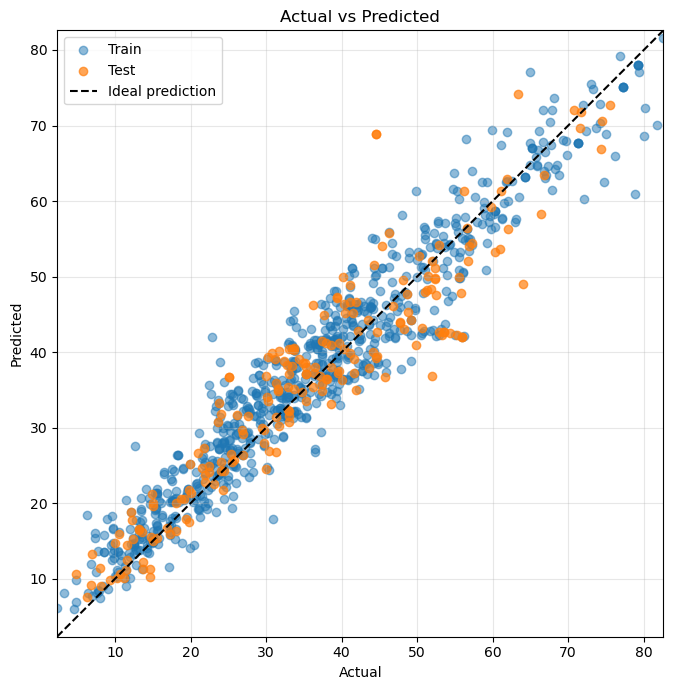

--- 精度評価 ---
RMSE :  train 4.7488   test 5.7342
MAE  :  train 3.7039    test 4.2297
R2   :  train 0.9206     teat 0.8724


In [4]:
# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

params = {
            "input_dim": X_train.shape[1],
            "output_dim": Y_train.shape[1],
            "hidden_layers": [224, 208, 192],
            "dropout_rate": 0.0,

            "epochs": 300,
            "learning_rate": 0.001,

            "device":device
            }

# 標準化
scaler_x = StandardScaler()
X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)

scaler_y = StandardScaler()
Y_train_scaled = scaler_y.fit_transform(Y_train)
Y_test_scaled = scaler_y.transform(Y_test)

# Tensorに変換（ここでGPU転送もできるが、データ量多い場合メモリ不足する。ここではbachごと伝送）
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
Y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
Y_test_tensor = torch.tensor(Y_test_scaled, dtype=torch.float32)


model, best_epoch = NN_train(params, X_train_tensor, Y_train_tensor, X_test_tensor, Y_test_tensor, log_disp=True)


# ==========================================
# 学習済みモデルの保存
# ==========================================
model_save_path = "./results/NN/NN_model.pth"

# 保存先ディレクトリを自動作成
Path(model_save_path).parent.mkdir(parents=True, exist_ok=True)


torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": X_train.shape[1],
        "output_dim": Y_train.shape[1],
        "hidden_layers": [224, 208, 192],
        "dropout_rate": 0.0,

        # X（入力）のスケーラー情報
        "scaler_x_mean": scaler_x.mean_,
        "scaler_x_scale": scaler_x.scale_,
        
        # Y（出力）のスケーラー情報
        "scaler_y_mean": scaler_y.mean_,
        "scaler_y_scale": scaler_y.scale_,
    },
    model_save_path
)

print("モデルを保存しました。")

# ==========================================
# 正解-予測プロット
# ==========================================
# 予測
with torch.no_grad():
    y_train_pred_scaled = model(X_train_tensor.to(device)).cpu().numpy()
    y_test_pred_scaled = model(X_test_tensor.to(device)).cpu().numpy()

# 元のスケールに戻す
y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled)
y_test_pred = scaler_y.inverse_transform(y_test_pred_scaled)

Plot_actual_vs_predict(Y_train,y_train_pred,Y_test,y_test_pred)

# ==========================================
# 精度評価
# ==========================================
evaluation_model(Y_train, y_train_pred, Y_test, y_test_pred)